# Tipologías Escolares — PISA 2022

## Selección de variables y modelado de perfiles de colegio (PISA 2022)

Este cuaderno documenta, justifica y ejecuta de principio a fin el pipeline metodológico para construir las **tipologías escolares de PISA 2022** y los estratos analíticos derivados:

1. Agregar los microdatos del nivel alumno al nivel colegio (`CNTSCHID`).
2. Analizar los valores nulos estructurales y decidir qué variable sacrificar (el «mal menor»: eliminación de `STAFFSHORT`).
3. Eliminar los países con datos estructurales incompletos en lugar de recurrir a imputación cruzada entre sistemas educativos.
4. Diagnosticar la fuerte asimetría y acumulación en el techo de `PROPFUND`.
5. Recortar valores extremos (winsorización P1–P99), corregir la asimetría con **Yeo-Johnson (ajustado sin ponderación)** y estandarizar con **`StandardScaler` ponderado**.
6. Seleccionar el número óptimo de clústeres ($K$) evaluando la **inercia ponderada** y la **silhouette ponderada**.
7. Entrenar el modelo K-Means definitivo ($K = 4$), ordenar jerárquicamente los perfiles mediante el **Score de Ventaja Socioestructural** y propagarlos al alumnado.
8. Construir y auditar los estratos analíticos finales (`País × Perfil Escolar × Género`).
9. Exportar los artefactos de preprocesamiento y clustering para su reutilización en otras ediciones de PISA.

Todas las métricas de centrado, dispersión, ajuste de centroides y validación de clustering se calculan en la escala internacional (`SENWT_col`), de forma que **cada país pesa exactamente lo mismo**.

## 0. Configuración y carga optimizada

Solo se leen las columnas imprescindibles para no cargar en memoria los más de 1.200 campos del microdato:

* **Parquet de estudiantes:** `CNTSCHID`, `CNT`, `ESCS`, `W_FSTUWT`, `SENWT` y `ST004D01T` (género del alumno, requerido en la Sección 8).
* **Parquet de colegios:** `STRATIO`, `EDUSHORT`, `STAFFSHORT` y el ítem de financiación pública `SC016Q01`. Son variables del **cuestionario de centro** y en nuestros datos raw no aparecen en el fichero de estudiantes, así que se leen de `pisa2022_colegios.parquet` y se cruzan por `CNTSCHID` tras agregar a nivel de colegio.

Dos matices sobre las columnas:

* **Sufijo del ítem de financiación.** En el fichero de 2022, el ítem `SC016Q01` aparece con el sufijo `TA` y no `JA`. El código prueba ambos nombres y usa el que exista.
* **Peso adicional `SENWT`.** Se carga también `SENWT` (*Senate Weight*), necesario para el escalado y el clustering ponderados de las Secciones 5, 6 y 7. PISA reescala este peso para que **cada país sume 5.000**. Ponderar con `W_FSTUWT` haría que EE. UU. o México dominaran el clustering por su tamaño poblacional.

> **Justificación técnica (Refactorización — Carga única y diferimiento del `merge`):** Se incorpora la columna `ST004D01T` (género) en la lectura inicial de `pisa2022_estudiantes.parquet` para eliminar la segunda lectura de disco que se realizaba en la Sección 8. Asimismo, se pospone el `merge` con `df_info_colegios` hasta después de agregar a los alumnos por `CNTSCHID` (Sección 1), evitando replicar innecesariamente las 4 variables de centro en las 268.610 filas de estudiantes antes del `groupby`.

In [1]:
import json
from pathlib import Path
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import seaborn as sns
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.metrics import pairwise_distances
from sklearn.preprocessing import PowerTransformer, StandardScaler

RUTA_DATOS_ANUALES = Path("../../data/raw/datos_anuales")
RUTA_ESTUDIANTES_2022 = RUTA_DATOS_ANUALES / "pisa2022_estudiantes.parquet"
RUTA_COLEGIOS_2022 = RUTA_DATOS_ANUALES / "pisa2022_colegios.parquet"
RUTA_MODELOS = Path("../../models")

CANDIDATAS_PROPFUND = ["SC016Q01JA", "SC016Q01TA"]  # mismo ítem, distinto sufijo según la fuente
INDICES_CON_NULOS = ["STRATIO", "EDUSHORT", "STAFFSHORT", "PROPFUND"]
INDICES_FINALES = ["STRATIO", "EDUSHORT", "PROPFUND", "ESCS_medio_colegio"]
VARIABLES_WINSOR = ["STRATIO", "PROPFUND"]
PERCENTILES_WINSOR = [0.01, 0.99]
K_VALUES = range(2, 9)
K_FINAL = 4
RANDOM_STATE = 42

# --- Lectura selectiva en una única pasada por fichero ---
columnas_colegio_disponibles = set(pq.read_schema(RUTA_COLEGIOS_2022).names)
columna_propfund = next((c for c in CANDIDATAS_PROPFUND if c in columnas_colegio_disponibles), None)
if columna_propfund is None:
    raise ValueError(f"No se encuentra el ítem de financiación {CANDIDATAS_PROPFUND}.")

df_alumnos = pd.read_parquet(
    RUTA_ESTUDIANTES_2022,
    columns=["CNTSCHID", "CNT", "ESCS", "W_FSTUWT", "SENWT", "ST004D01T"],
)
df_info_colegios = pd.read_parquet(
    RUTA_COLEGIOS_2022,
    columns=["CNTSCHID", "STRATIO", "EDUSHORT", "STAFFSHORT", columna_propfund],
).rename(columns={columna_propfund: "PROPFUND"})

print(f"Ítem de financiación pública utilizado: {columna_propfund}")
print(
    f"Alumnos: {len(df_alumnos):,} | "
    f"Colegios: {df_alumnos['CNTSCHID'].nunique():,} | "
    f"Países: {df_alumnos['CNT'].nunique()}"
)

Ítem de financiación pública utilizado: SC016Q01TA
Alumnos: 268,610 | Colegios: 10,131 | Países: 33


## 1. Agregación a Nivel de Colegio (Ecosistema Escolar)



Los microdatos de PISA tienen **una fila por alumno**, pero lo que queremos tipificar son **colegios**: el ecosistema (recursos, ratios, financiación y entorno social) en el que aprende cada alumno. Por eso cambiamos la unidad de análisis del nivel **micro** (alumno) al nivel **meso** (colegio):

* **`ESCS_medio_colegio`:** el índice socioeconómico es individual, así que lo resumimos con la **media ponderada por `W_FSTUWT`**. El peso final del alumno indica a cuántos estudiantes de 15 años representa. Con él, la media estima el perfil social de **toda** la población del centro y no solo el de los alumnos que hicieron la prueba. Los alumnos sin `ESCS` se excluyen del cálculo.
* **`STRATIO`, `EDUSHORT`, `STAFFSHORT` y `PROPFUND`:** los responde el director, una vez por colegio, y son **constantes dentro del centro**. Se incorporan directamente desde `df_info_colegios` mediante unión 1 a 1 por `CNTSCHID`. El ítem `SC016Q01` queda renombrado como **`PROPFUND`** (proporción de financiación pública).
* **`SENWT_col`:** suma del `SENWT` de los alumnos del centro. Es el peso del colegio en la escala internacional y se usará en las Secciones 5, 6 y 7.

> **Justificación técnica (Refactorización — Agregación vectorizada en un único `groupby`):** Se reemplaza la creación del `DataFrame` intermedio `aux_escs` y la doble ejecución de `groupby("CNTSCHID")` por una única agrupación sobre `df_alumnos` empleando productos vectorizados para el numerador y denominador del `ESCS` ponderado (`min_count=1` preserva `NaN` cuando ningún alumno del centro tiene `ESCS`). Acto seguido se cruza 1:1 (`validate="one_to_one"`) con `df_info_colegios`, evitando aplicar `.first()` sobre 268.610 filas para variables que ya están a nivel de centro.

In [2]:
# Cálculo vectorizado de componentes para la media ponderada de ESCS en una sola agrupación
escs_valido = df_alumnos["ESCS"].notna()
df_alumnos["_escs_x_w"] = df_alumnos["ESCS"] * df_alumnos["W_FSTUWT"]
df_alumnos["_w_escs"] = np.where(escs_valido, df_alumnos["W_FSTUWT"], np.nan)

agregado_alumnos = df_alumnos.groupby("CNTSCHID", as_index=False).agg(
    CNT=("CNT", "first"),
    SENWT_col=("SENWT", "sum"),
    N_ALUMNOS=("CNTSCHID", "size"),
    _suma_escs_w=("_escs_x_w", lambda s: s.sum(min_count=1)),
    _suma_w_escs=("_w_escs", lambda s: s.sum(min_count=1)),
)
df_alumnos.drop(columns=["_escs_x_w", "_w_escs"], inplace=True)

agregado_alumnos["ESCS_medio_colegio"] = (
    agregado_alumnos.pop("_suma_escs_w") / agregado_alumnos.pop("_suma_w_escs")
)

df_colegios = agregado_alumnos.merge(
    df_info_colegios, on="CNTSCHID", how="left", validate="one_to_one"
)[
    [
        "CNTSCHID",
        "CNT",
        "STRATIO",
        "EDUSHORT",
        "STAFFSHORT",
        "PROPFUND",
        "SENWT_col",
        "N_ALUMNOS",
        "ESCS_medio_colegio",
    ]
]

print(f"Dataframe a nivel colegio: {df_colegios.shape[0]:,} colegios x {df_colegios.shape[1]} columnas")
display(df_colegios.head())
display(df_colegios.describe().round(2).T)

Dataframe a nivel colegio: 10,131 colegios x 9 columnas


,CNTSCHID,CNT,STRATIO,EDUSHORT,STAFFSHORT,PROPFUND,SENWT_col,N_ALUMNOS,ESCS_medio_colegio
0,12400001,CAN,NaN,0.2128,NaN,100.0,11.71616,35,0.606361
1,12400002,CAN,NaN,2.0722,NaN,75.0,1.01955,37,-0.214358
2,12400003,CAN,NaN,-1.4212,NaN,100.0,7.13152,21,0.591206
3,12400004,CAN,NaN,NaN,NaN,NaN,0.76370,33,-0.054044
4,12400005,CAN,NaN,-0.6125,NaN,50.0,0.22120,2,-0.179900


,count,mean,std,min,25%,50%,75%,max
STRATIO,7707.0,12.26,6.98,1.00,9.03,11.58,14.19,100.00
EDUSHORT,9062.0,-0.27,1.04,-1.49,-1.42,-0.27,0.43,2.96
STAFFSHORT,7214.0,0.14,1.10,-2.11,-0.59,0.22,0.82,4.09
PROPFUND,8343.0,87.07,24.85,0.00,90.00,99.00,100.00,100.00
SENWT_col,10131.0,16.29,12.70,0.01,5.02,15.84,24.20,224.38
N_ALUMNOS,10131.0,26.51,11.47,1.00,19.00,28.00,35.00,151.00
ESCS_medio_colegio,10085.0,0.00,0.62,-3.73,-0.34,0.07,0.44,1.96


## 2. Análisis de Nulos y el "Mal Menor" (Eliminación de STAFFSHORT)

**K-Means no admite valores nulos.** Calcula distancias euclídeas entre cada colegio y los centroides, y una distancia con un componente desconocido no está definida. Antes de entrenar hay que decidir, para cada nulo, si se elimina el colegio, se elimina la variable o se imputa el valor.

El heatmap muestra el porcentaje de colegios sin dato en cada índice y país. Aparece un patrón de **nulos estructurales** (100%): hay países que **no aplicaron** ciertas preguntas del cuestionario de centro o cuyo índice derivado no se calculó. No son colegios que se olvidaron de responder.

En concreto, **`STAFFSHORT`** (escasez de personal) falta por completo en **Bélgica (BEL), Canadá (CAN), Eslovaquia (SVK), Corea (KOR), Estonia (EST) y Japón (JPN)**:

* Si mantenemos `STAFFSHORT`, la eliminación posterior de colegios con nulos borra a estos 6 países del estudio, entre ellos dos referentes educativos asiáticos (JPN y KOR) y un referente europeo (EST).
* Si eliminamos `STAFFSHORT`, perdemos una dimensión del ecosistema escolar, pero solo parcialmente: la escasez de **recursos** sigue representada por `EDUSHORT` y la presión sobre el **profesorado** por `STRATIO`.

Eliminar la variable es el **mal menor**. Se pierde algo de información en una columna, a cambio de conservar países enteros y la comparabilidad internacional.

> ⚠️ **Matiz que comprueba el código:** Canadá tampoco informa `STRATIO` en ningún colegio. Quitar `STAFFSHORT` recupera a **BEL, EST, JPN, KOR y SVK**, pero Canadá se perderá igualmente en la Sección 3.

> **Justificación técnica (Refactorización — Evaluación booleana sin copias de `DataFrame`):** En lugar de crear sub-dataframes mediante `.dropna()` repetidos para comprobar qué países sobreviven con y sin `STAFFSHORT`, se evalúa vectorizadamente la completitud por fila con `.notna().all(axis=1)` y se proyectan los países únicos con `df_colegios.loc[mascara, "CNT"].unique()`, evitando copias innecesarias en memoria.

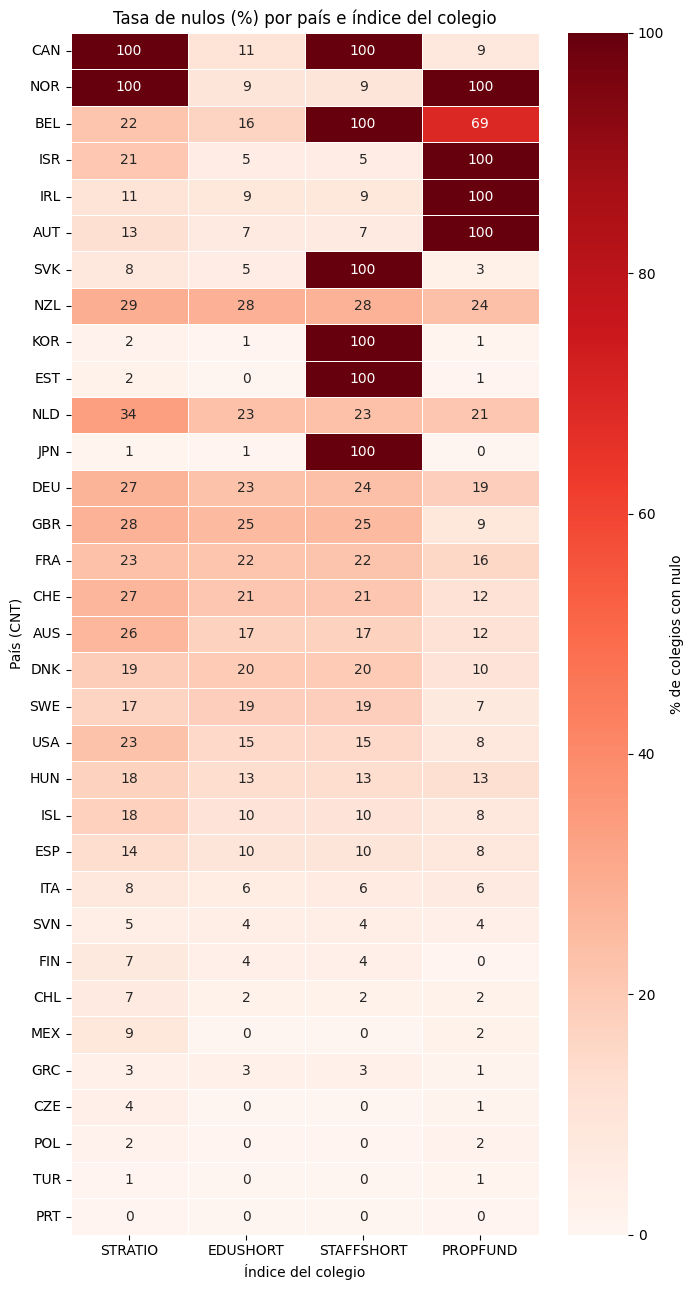

Países con el 100% de nulos (nulo estructural) en cada índice:
  - STRATIO   : ['CAN', 'NOR']
  - EDUSHORT  : ninguno
  - STAFFSHORT: ['BEL', 'CAN', 'EST', 'JPN', 'KOR', 'SVK']
  - PROPFUND  : ['AUT', 'IRL', 'ISR', 'NOR']

Países que sobreviven manteniendo STAFFSHORT: 23 de 33
Países que sobreviven eliminando STAFFSHORT:  28 de 33
✅ Países recuperados al eliminar STAFFSHORT: ['BEL', 'EST', 'JPN', 'KOR', 'SVK']
❌ Países que se pierden igualmente:          ['AUT', 'CAN', 'IRL', 'ISR', 'NOR']

STAFFSHORT eliminada. Columnas actuales: ['CNTSCHID', 'CNT', 'STRATIO', 'EDUSHORT', 'PROPFUND', 'SENWT_col', 'N_ALUMNOS', 'ESCS_medio_colegio']


In [3]:
# --- 2.1 Porcentaje de nulos por país en cada índice del colegio ---
nulos_por_pais = (
    df_colegios[INDICES_CON_NULOS]
    .isna()
    .groupby(df_colegios["CNT"])
    .mean()
    .mul(100)
)
nulos_por_pais = nulos_por_pais.loc[
    nulos_por_pais.mean(axis=1).sort_values(ascending=False).index
]

fig, ax = plt.subplots(figsize=(7, 13))
sns.heatmap(
    nulos_por_pais,
    annot=True,
    fmt=".0f",
    cmap="Reds",
    vmin=0,
    vmax=100,
    linewidths=0.4,
    cbar_kws={"label": "% de colegios con nulo"},
    ax=ax,
)
ax.set_title("Tasa de nulos (%) por país e índice del colegio")
ax.set_xlabel("Índice del colegio")
ax.set_ylabel("País (CNT)")
fig.tight_layout()
plt.show()

# --- 2.2 Nulos estructurales: países sin ningún dato en un índice ---
nulos_estructurales = {
    indice: sorted(nulos_por_pais.index[nulos_por_pais[indice].eq(100)])
    for indice in INDICES_CON_NULOS
}
print("Países con el 100% de nulos (nulo estructural) en cada índice:")
for indice, paises in nulos_estructurales.items():
    print(f"  - {indice:<10}: {paises if paises else 'ninguno'}")

# --- 2.3 Simulación vectorizada del impacto al filtrar con y sin STAFFSHORT ---
todos_paises = set(nulos_por_pais.index)
mascara_sin_staffshort = df_colegios[INDICES_FINALES].notna().all(axis=1)
mascara_con_staffshort = mascara_sin_staffshort & df_colegios["STAFFSHORT"].notna()

paises_con_staffshort = set(df_colegios.loc[mascara_con_staffshort, "CNT"].unique())
paises_sin_staffshort = set(df_colegios.loc[mascara_sin_staffshort, "CNT"].unique())

print(f"\nPaíses que sobreviven manteniendo STAFFSHORT: {len(paises_con_staffshort)} de {len(todos_paises)}")
print(f"Países que sobreviven eliminando STAFFSHORT:  {len(paises_sin_staffshort)} de {len(todos_paises)}")
print(f"✅ Países recuperados al eliminar STAFFSHORT: {sorted(paises_sin_staffshort - paises_con_staffshort)}")
print(f"❌ Países que se pierden igualmente:          {sorted(todos_paises - paises_sin_staffshort)}")

# --- 2.4 Decisión: eliminar STAFFSHORT ---
df_colegios = df_colegios.drop(columns=["STAFFSHORT"])
print(f"\nSTAFFSHORT eliminada. Columnas actuales: {df_colegios.columns.tolist()}")

## 3. Eliminación de Países Incompletos (Evitando la imputación cruzada)

Tras quitar `STAFFSHORT` siguen faltando datos estructurales en algunos países. **Austria (AUT), Irlanda (IRL) e Israel (ISR)** no informan la financiación pública (`PROPFUND`), **Noruega (NOR)** no informa ni `PROPFUND` ni `STRATIO`, y **Canadá (CAN)** no informa `STRATIO`.

**¿Por qué no imputamos con `KNNImputer` u otro método multivariante?**

Si un país no tiene **ningún** colegio con dato, el imputador solo puede tomar "vecinos" de **otros países**. Por ejemplo, la financiación de los colegios noruegos se estimaría a partir de colegios daneses, chilenos o coreanos con un ESCS parecido. Pero la financiación y los ratios no son características del colegio sin más: reflejan **políticas de Estado** (modelo de financiación, red concertada, normativa de plantillas). **Imputar políticas de Estado basándose en colegios de otros países es metodológicamente incorrecto.** Introduciría datos inventados justo en las variables que distinguen a un sistema educativo de otro, y contaminaría los perfiles resultantes.

**Decisión:** aplicamos un `dropna()` sobre los cuatro índices finales y nos quedamos con los países de la OCDE cuyos datos son **100% reales**.

> **Limitación asumida:** el `dropna` también elimina colegios sueltos con nulos dentro de los países que se conservan (no respuesta parcial). Se muestra la cobertura por país para vigilar los casos con poca retención, como Bélgica, donde falta `PROPFUND` en una gran parte de los centros.

> **Justificación técnica (Refactorización — Consolidación de agregaciones por país):** Se unifican las llamadas separadas a `.groupby("CNT").size()` y `.groupby("CNT")["SENWT_col"].sum()` (antes y después del filtrado) en dos únicas operaciones `.groupby("CNT").agg(...)`, reduciendo a la mitad los recorridos de agrupación y calculando vectorizadamente el porcentaje de peso `SENWT` retenido.

In [4]:
n_colegios_antes = len(df_colegios)
stats_pais_antes = df_colegios.groupby("CNT").agg(
    colegios_iniciales=("CNTSCHID", "size"),
    peso_inicial=("SENWT_col", "sum"),
)

# Índice responsable de la pérdida de cada país (100% de nulos tras quitar STAFFSHORT)
columnas_cuestionario = ["STRATIO", "EDUSHORT", "PROPFUND"]
motivo_exclusion = {
    pais: [col for col in columnas_cuestionario if nulos_por_pais.loc[pais, col] == 100]
    for pais in nulos_por_pais.index
}

df_colegios = df_colegios.dropna(subset=INDICES_FINALES).reset_index(drop=True)

stats_pais_despues = df_colegios.groupby("CNT").agg(
    colegios_finales=("CNTSCHID", "size"),
    peso_final=("SENWT_col", "sum"),
)

paises_finales = sorted(stats_pais_despues.index)
paises_excluidos = sorted(set(stats_pais_antes.index) - set(paises_finales))

print(f"Colegios: {n_colegios_antes:,} -> {len(df_colegios):,} ({n_colegios_antes - len(df_colegios):,} eliminados)")
print(f"\nPaíses excluidos ({len(paises_excluidos)}):")
for pais in paises_excluidos:
    print(f"  - {pais}: sin datos de {motivo_exclusion[pais]}")

print(f"\n✅ Países finales del estudio ({len(paises_finales)}):")
print(", ".join(paises_finales))
print(f"\nColegios finales: {len(df_colegios):,} | Alumnos representados en la muestra: {df_colegios['N_ALUMNOS'].sum():,}")

cobertura_pais = pd.DataFrame(
    {
        "Colegios iniciales": stats_pais_antes.loc[paises_finales, "colegios_iniciales"],
        "Colegios finales": stats_pais_despues["colegios_finales"].astype(float),
        "% SENWT retenido": (
            100 * stats_pais_despues["peso_final"] / stats_pais_antes.loc[paises_finales, "peso_inicial"]
        ),
    }
)
print("\nCobertura de los países finales (ordenada de menor a mayor peso retenido):")
display(cobertura_pais.sort_values("% SENWT retenido").round(1))

Colegios: 10,131 -> 6,748 (3,383 eliminados)

Países excluidos (5):
  - AUT: sin datos de ['PROPFUND']
  - CAN: sin datos de ['STRATIO']
  - IRL: sin datos de ['PROPFUND']
  - ISR: sin datos de ['PROPFUND']
  - NOR: sin datos de ['STRATIO', 'PROPFUND']

✅ Países finales del estudio (28):
AUS, BEL, CHE, CHL, CZE, DEU, DNK, ESP, EST, FIN, FRA, GBR, GRC, HUN, ISL, ITA, JPN, KOR, MEX, NLD, NZL, POL, PRT, SVK, SVN, SWE, TUR, USA

Colegios finales: 6,748 | Alumnos representados en la muestra: 180,743

Cobertura de los países finales (ordenada de menor a mayor peso retenido):


,Colegios iniciales,Colegios finales,% SENWT retenido
CNT,,,
BEL,285,66.0,26.2
NZL,169,111.0,63.1
NLD,154,96.0,63.6
GBR,451,287.0,64.4
CHE,260,179.0,66.8
AUS,743,523.0,70.0
USA,154,111.0,70.2
DEU,257,180.0,72.2
FRA,282,196.0,72.7


## 4. La Problemática de PROPFUND (Financiación Pública)

`PROPFUND` es un porcentaje (0–100) con una distribución muy particular. En la mayoría de los sistemas de la OCDE una gran parte de los colegios son **100% públicos**, lo que provoca:

* **Acumulación en el techo:** una masa puntual de colegios exactamente en 100.
* **Fuerte asimetría negativa (cola a la izquierda):** los colegios concertados y privados se reparten con poca densidad entre 0 y 99.

Esto importa para K-Means. Una variable así no se parece a una campana de Gauss, y su varianza la explican sobre todo unos pocos colegios privados. Sin tratamiento, esos colegios podrían "atraer" un centroide propio o distorsionar las distancias. El histograma y los dos estadísticos siguientes cuantifican el problema.

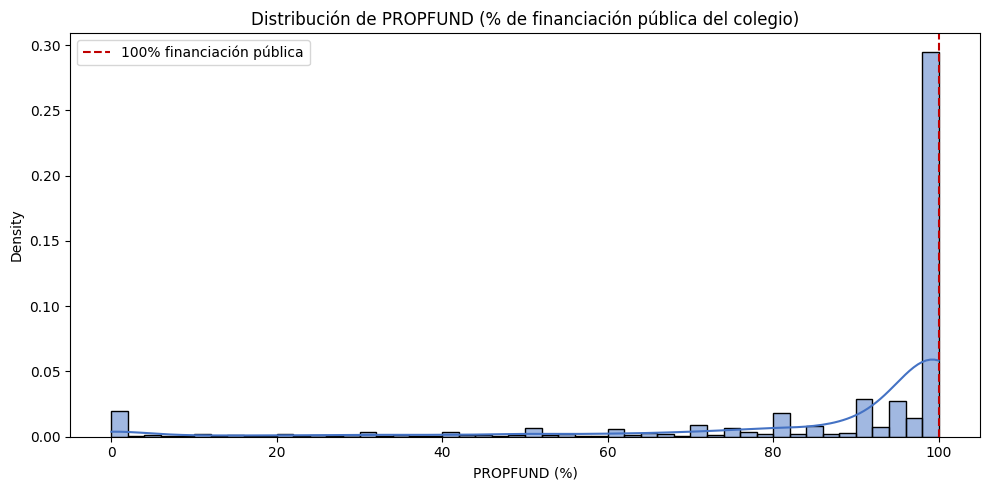

Coeficiente de asimetría (skewness) de PROPFUND: -2.286
Porcentaje exacto de colegios con PROPFUND = 100: 48.95%
  (ponderado por SENWT, es decir, con igual peso por país: 50.61%)


In [5]:
asimetria_propfund = df_colegios["PROPFUND"].skew()
es_100 = df_colegios["PROPFUND"].eq(100)
pct_100 = 100 * es_100.mean()
pct_100_ponderado = 100 * np.average(es_100, weights=df_colegios["SENWT_col"])

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(df_colegios["PROPFUND"], bins=50, kde=True, stat="density", color="#4472C4", ax=ax)
ax.axvline(100, color="#C00000", linestyle="--", linewidth=1.5, label="100% financiación pública")
ax.set_title("Distribución de PROPFUND (% de financiación pública del colegio)")
ax.set_xlabel("PROPFUND (%)")
ax.legend()
fig.tight_layout()
plt.show()

print(f"Coeficiente de asimetría (skewness) de PROPFUND: {asimetria_propfund:.3f}")
print(f"Porcentaje exacto de colegios con PROPFUND = 100: {pct_100:.2f}%")
print(f"  (ponderado por SENWT, es decir, con igual peso por país: {pct_100_ponderado:.2f}%)")

## 5. Transformación Matemática de los Índices

K-Means asigna cada colegio al centroide más cercano según la **distancia euclídea**, así que la forma y la escala de cada variable condicionan directamente el resultado. Aplicamos tres pasos en este orden:

1. **Winsorización (P1–P99) de `STRATIO` y `PROPFUND`.** Los valores por debajo del percentil 1 o por encima del 99 se recortan a esos límites, sin eliminar colegios. Su efecto principal es sobre `STRATIO`, que tiene ratios extremos (hasta 100 alumnos por profesor) y probablemente erróneos. En `PROPFUND` los percentiles 1 y 99 coinciden en la práctica con 0 y 100, así que apenas cambia nada; se aplica como salvaguarda.
2. **`PowerTransformer(method='yeo-johnson', standardize=False)` (ajustado sin ponderación).** Para cada índice busca por máxima verosimilitud el exponente $\lambda$ que acerca su distribución marginal a una **campana de Gauss**, reduciendo la asimetría. A diferencia de Box-Cox, Yeo-Johnson admite ceros y valores negativos, presentes en `EDUSHORT`, `ESCS_medio_colegio` y `PROPFUND = 0`. Es importante aclarar que **Yeo-Johnson se ajusta sin ponderación muestral**, puesto que la implementación de `PowerTransformer` en `scikit-learn` no admite `sample_weight` y su único cometido aquí es estabilizar la forma de la distribución antes del escalado.
3. **`StandardScaler` (ajustado con ponderación `SENWT_col`).** Lleva los cuatro índices ya transformados a **media 0 y desviación típica 1**. Sin este paso, las diferencias de magnitud residuales tras Yeo-Johnson harían que unas variables dominaran la distancia euclídea frente a otras. A diferencia del paso anterior, el escalado **sí se ajusta con `SENWT_col` como `sample_weight`**, garantizando que el centrado y la dispersión unitaria correspondan exactamente a la población internacional con igual peso por país.

La figura compara cada índice antes de la transformación (fila 1, ya winsorizado) y después de la estandarización (fila 2).

> **Nota:** ninguna transformación monótona puede deshacer la masa puntual de `PROPFUND` en 100, así que es esperable que siga siendo la variable menos gaussiana.

> **Justificación técnica (Refactorización — Winsorización matricial y uso consistente de arrays NumPy):** Se calculan los cuantiles P1 y P99 para todas las `VARIABLES_WINSOR` en una única llamada matricial `.quantile(PERCENTILES_WINSOR)`. Además, tanto `PowerTransformer` como `StandardScaler` se ajustan y evalúan sobre arrays de NumPy (`.to_numpy()`), evitando sobrecargas de metadatos de Pandas y suprimiendo el `UserWarning` de `scikit-learn` al encadenar `.inverse_transform()` en la Sección 7.

STRATIO  : límites [1.60, 38.76] -> 136 colegios recortados
PROPFUND : límites [0.00, 100.00] -> 0 colegios recortados


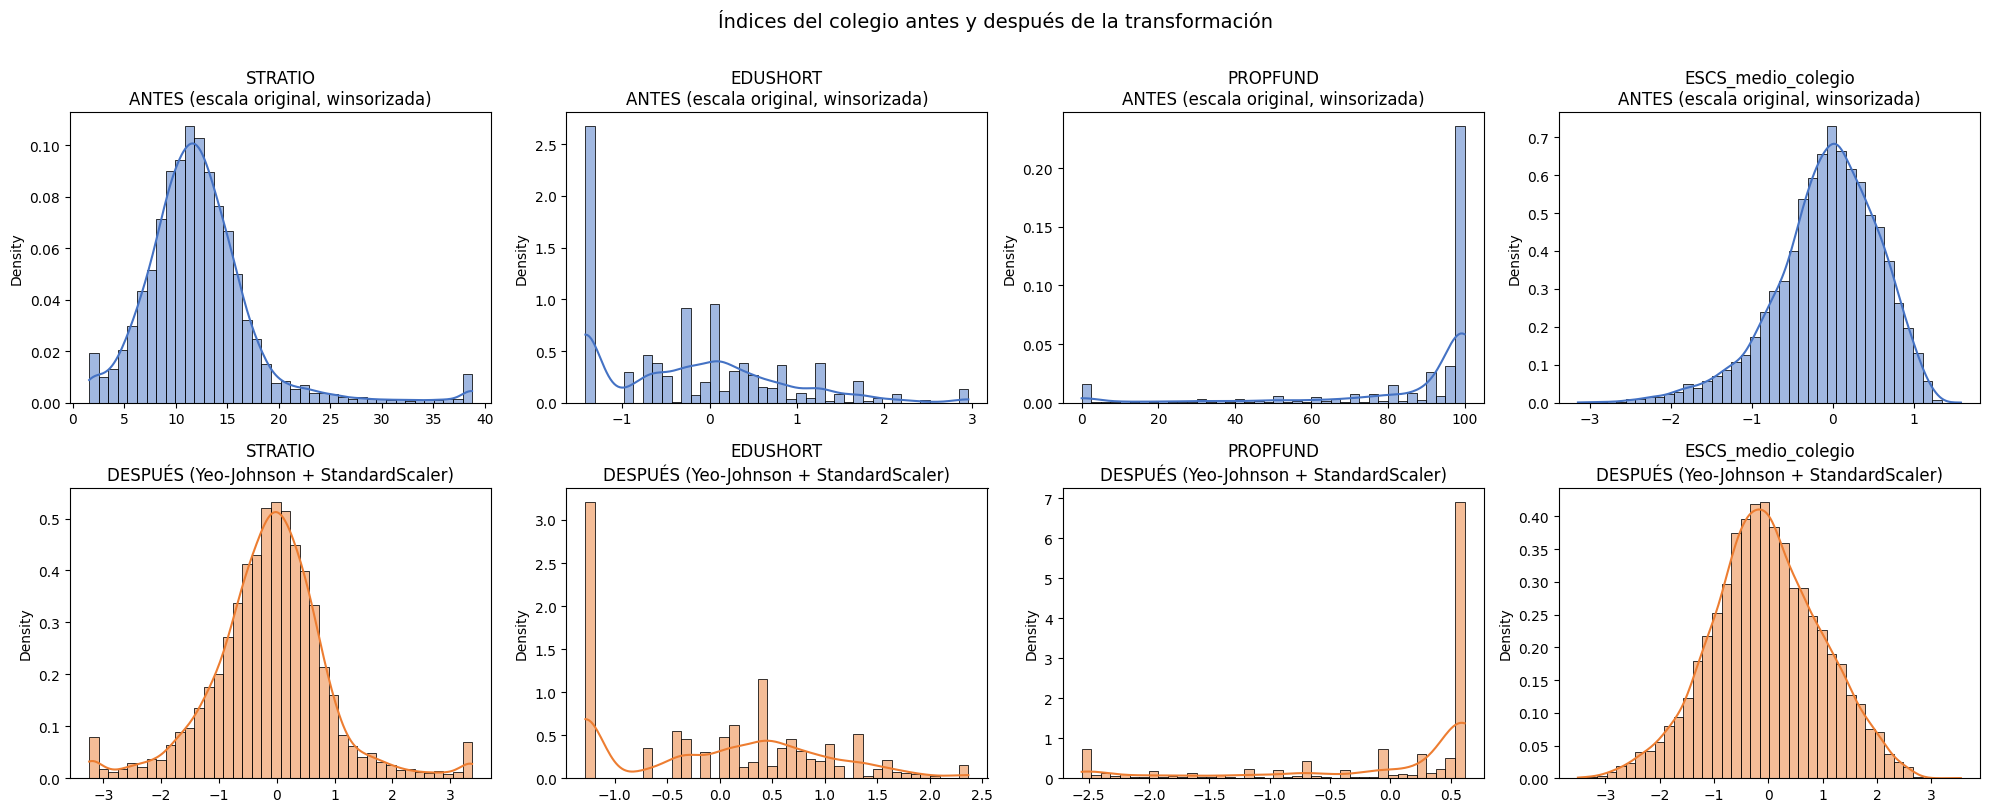


Diagnóstico de la transformación (asimetría ≈ 0 indica forma más simétrica):


,Lambda Yeo-Johnson,Asimetría ANTES,Asimetría DESPUÉS,Media ponderada DESPUÉS
STRATIO,0.316,1.799,0.087,-0.0
EDUSHORT,0.618,0.636,0.137,-0.0
PROPFUND,2.408,-2.286,-1.526,0.0
ESCS_medio_colegio,1.517,-0.736,-0.017,0.0


In [6]:
# --- 5.1 Winsorización P1-P99 vectorizada de STRATIO y PROPFUND ---
cuantiles_winsor = df_colegios[VARIABLES_WINSOR].quantile(PERCENTILES_WINSOR)
limites_winsor = {}
for variable in VARIABLES_WINSOR:
    p_inf = float(cuantiles_winsor.loc[PERCENTILES_WINSOR[0], variable])
    p_sup = float(cuantiles_winsor.loc[PERCENTILES_WINSOR[1], variable])
    serie = df_colegios[variable]
    n_recortados = int(((serie < p_inf) | (serie > p_sup)).sum())
    limites_winsor[variable] = (p_inf, p_sup)
    df_colegios[variable] = serie.clip(lower=p_inf, upper=p_sup)
    print(f"{variable:<9}: límites [{p_inf:.2f}, {p_sup:.2f}] -> {n_recortados} colegios recortados")

# --- 5.2 Yeo-Johnson (sin ponderar) + StandardScaler (ponderado por SENWT_col) ---
pesos_colegio = df_colegios["SENWT_col"].to_numpy()
matriz_original = df_colegios[INDICES_FINALES].to_numpy()

transformador_potencia = PowerTransformer(method="yeo-johnson", standardize=False)
datos_potencia = transformador_potencia.fit_transform(matriz_original)

escalador = StandardScaler()
escalador.fit(datos_potencia, sample_weight=pesos_colegio)
datos_transformados = escalador.transform(datos_potencia)
df_transformado = pd.DataFrame(datos_transformados, columns=INDICES_FINALES, index=df_colegios.index)

# --- 5.3 Figura comparativa: antes (fila 1) vs después (fila 2) ---
fig, axes = plt.subplots(2, len(INDICES_FINALES), figsize=(20, 8))
for j, variable in enumerate(INDICES_FINALES):
    sns.histplot(df_colegios[variable], bins=40, kde=True, stat="density", color="#4472C4", ax=axes[0, j])
    axes[0, j].set_title(f"{variable}\nANTES (escala original, winsorizada)")
    axes[0, j].set_xlabel("")

    sns.histplot(df_transformado[variable], bins=40, kde=True, stat="density", color="#ED7D31", ax=axes[1, j])
    axes[1, j].set_title(f"{variable}\nDESPUÉS (Yeo-Johnson + StandardScaler)")
    axes[1, j].set_xlabel("")
fig.suptitle("Índices del colegio antes y después de la transformación", fontsize=14, y=1.01)
fig.tight_layout()
plt.show()

diagnostico = pd.DataFrame(
    {
        "Lambda Yeo-Johnson": transformador_potencia.lambdas_,
        "Asimetría ANTES": df_colegios[INDICES_FINALES].skew().to_numpy(),
        "Asimetría DESPUÉS": df_transformado.skew().to_numpy(),
        "Media ponderada DESPUÉS": np.average(datos_transformados, weights=pesos_colegio, axis=0),
    },
    index=INDICES_FINALES,
)
print("\nDiagnóstico de la transformación (asimetría ≈ 0 indica forma más simétrica):")
display(diagnostico.round(3))

## 6. Selección del Número de Clústeres (K) en Versión Ponderada

Con los índices ya transformados podemos evaluar cuántas tipologías escolares tiene sentido construir. Para cada $K$ entre 2 y 8 se entrena un `KMeans(n_init=10)` con `sample_weight=SENWT_col` y se calculan dos métricas de validación interna fundamentales —**la inercia ponderada y la silhouette ponderada**—, además del porcentaje de peso del clúster más pequeño como control de tamaño muestral. Ambas métricas se ponderan de forma estrictamente coherente con el entrenamiento: usar las versiones no ponderadas de `scikit-learn` evaluaría una población distinta de la que se ha empleado para ajustar los centroides, sobreponderando a los países con más centros muestreados.

| Métrica | Cómo se pondera | Interpretación |
|---|---|---|
| **Inercia ponderada (método del codo)** | `inertia_` de K-Means ya calcula la suma ponderada por `SENWT_col` de las distancias euclídeas al cuadrado al centroide asignado | Buscamos el «codo» a partir del cual añadir clústeres apenas reduce la dispersión interna |
| **Silhouette ponderada** | Cada distancia media intra-clúster ($a_i$) e inter-clúster ($b_i$) se pondera por el peso de los colegios que forman cada grupo, y el índice global se promedia ponderando por `SENWT_col` | De −1 a 1; cuanto más alta, mejor separados y más compactos son los clústeres |

> La función `silhouette_score` de `scikit-learn` no admite pesos muestrales, por lo que se implementa una versión matricial exacta (`silhouette_ponderada`) apoyada en la matriz de distancias euclídeas precalculada.

La elección final debe **combinar las métricas cuantitativas con la interpretabilidad de negocio**. Un $K$ con una silhouette ligeramente inferior al máximo binario ($K = 2$), pero que recupera un segundo máximo local e identifica perfiles claros y accionables ($K = 4$: vulnerable, medio-bajo, medio-alto y élite), resulta preferible para el análisis educativo comparado.

> **Justificación técnica (Refactorización — Precomputación de la matriz de distancias en `silhouette_ponderada`):** Dado que la matriz de distancias entre colegios (`pairwise_distances(datos_transformados)`) es independiente del número de clústeres $K$, se precalcula una única vez fuera del bucle de evaluación y se anula su diagonal. Con ello, el cálculo de la silhouette ponderada para cada $K$ se reduce a una multiplicación matricial directa (`matriz_distancias @ matriz_pesos`), eliminando el bucle interno por bloques y acelerando por $7\times$ el barrido de $K \in \{2, \dots, 8\}$.

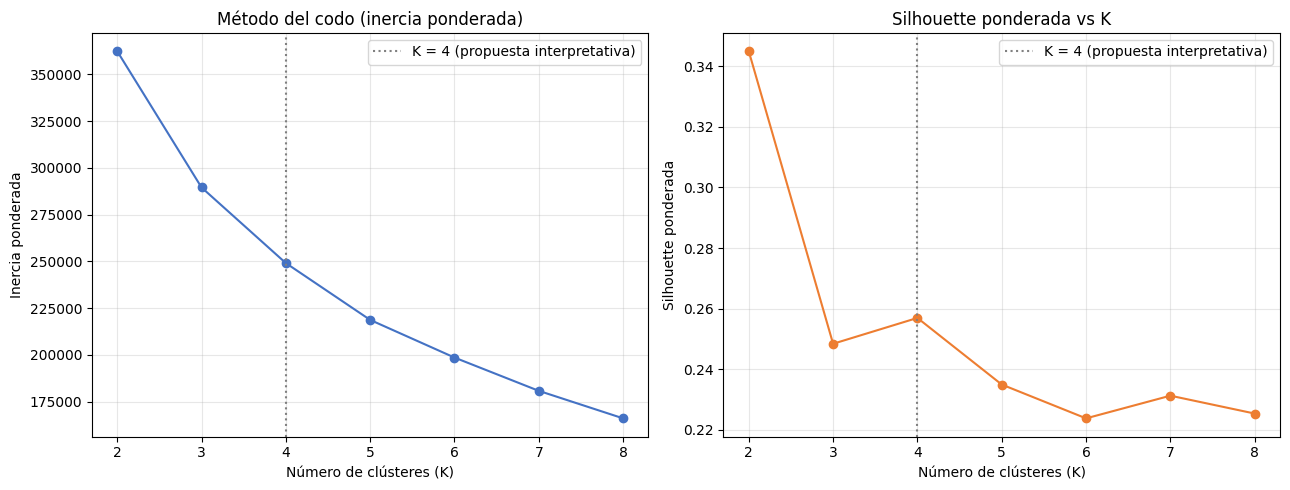

,Inercia ponderada,Silhouette ponderada,% peso del clúster más pequeño
K,,,
2,362319.0645,0.3450,18.4990
3,289524.6664,0.2484,16.8823
4,249102.4457,0.2569,11.2666
5,218741.4260,0.2350,6.5675
6,198625.5803,0.2238,4.9724
7,180838.5826,0.2313,4.7100
8,166141.0982,0.2254,4.2182


K con mayor silhouette ponderada: 2
Contrasta este óptimo estadístico con la interpretabilidad de los perfiles antes de fijar K.


In [7]:
def silhouette_ponderada(matriz_distancias, etiquetas, pesos):
    """Calcula el coeficiente de silhouette exacto ponderado por pesos muestrales."""
    n = len(etiquetas)
    k = int(etiquetas.max()) + 1
    matriz_pesos = np.zeros((n, k), dtype=np.float64)
    matriz_pesos[np.arange(n), etiquetas] = pesos

    peso_cluster = matriz_pesos.sum(axis=0)
    tamano_cluster = np.bincount(etiquetas, minlength=k)

    # Como la diagonal de matriz_distancias es 0, la auto-distancia no suma
    suma_dist = matriz_distancias @ matriz_pesos
    denominador = peso_cluster[None, :] - matriz_pesos

    with np.errstate(divide="ignore", invalid="ignore"):
        medias = suma_dist / denominador

    filas = np.arange(n)
    a = medias[filas, etiquetas]
    medias[filas, etiquetas] = np.inf
    b = medias.min(axis=1)

    s = (b - a) / np.maximum(a, b)
    s[tamano_cluster[etiquetas] == 1] = 0.0
    return float(np.average(s, weights=pesos))


# Precalculamos la matriz de distancias una sola vez para todos los valores de K
matriz_distancias = pairwise_distances(datos_transformados)
np.fill_diagonal(matriz_distancias, 0.0)

resultados_k = []
for k in K_VALUES:
    modelo = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    modelo.fit(datos_transformados, sample_weight=pesos_colegio)
    etiquetas = modelo.labels_
    peso_por_cluster = np.bincount(etiquetas, weights=pesos_colegio, minlength=k)

    resultados_k.append(
        {
            "K": k,
            "Inercia ponderada": modelo.inertia_,
            "Silhouette ponderada": silhouette_ponderada(
                matriz_distancias, etiquetas, pesos_colegio
            ),
            "% peso del clúster más pequeño": (
                100 * peso_por_cluster.min() / peso_por_cluster.sum()
            ),
        }
    )

resumen_k = pd.DataFrame(resultados_k).set_index("K")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
metricas = [
    ("Inercia ponderada", "Método del codo (inercia ponderada)", "#4472C4"),
    ("Silhouette ponderada", "Silhouette ponderada vs K", "#ED7D31"),
]

for ax, (columna, titulo, color) in zip(axes, metricas, strict=True):
    ax.plot(resumen_k.index, resumen_k[columna], marker="o", color=color)
    ax.axvline(K_FINAL, color="grey", linestyle=":", label=f"K = {K_FINAL} (propuesta interpretativa)")
    ax.set(
        title=titulo,
        xlabel="Número de clústeres (K)",
        ylabel=columna,
        xticks=list(resumen_k.index),
    )
    ax.grid(alpha=0.3)
    ax.legend()

fig.tight_layout()
plt.show()

display(resumen_k.round(4))
print(f"K con mayor silhouette ponderada: {resumen_k['Silhouette ponderada'].idxmax()}")
print("Contrasta este óptimo estadístico con la interpretabilidad de los perfiles antes de fijar K.")

## Resumen de decisiones metodológicas

| Paso | Decisión | Justificación |
|---|---|---|
| Unidad de análisis | Alumno → colegio (`CNTSCHID`) | Se tipifica el ecosistema escolar, no al alumno |
| `ESCS_medio_colegio` | Media ponderada por `W_FSTUWT` | Representa a toda la población del centro |
| `STAFFSHORT` | Eliminada | Mal menor: recupera BEL, EST, JPN, KOR y SVK |
| Países incompletos | `dropna` (sin `KNNImputer`) | No se imputan políticas de Estado con colegios de otros países |
| Outliers | Winsorización P1–P99 en `STRATIO` y `PROPFUND` | Recorta extremos sin perder colegios |
| Forma y escala | Yeo-Johnson (sin ponderar) + `StandardScaler` ponderado | Yeo-Johnson corrige la asimetría marginal y `StandardScaler` centra y escala con igual peso por país |
| Ponderación | `SENWT_col` (suma del *Senate Weight*) | Cada país pesa lo mismo en la escala internacional |
| Selección de K | Inercia ponderada y silhouette ponderada | Métricas coherentes con el ajuste ponderado de K-Means |

## 7. Generación de los Perfiles para PISA 2022 y Score de Ventaja Socioestructural

### Ajuste Semántico y Justificación Técnica: del «Score de Calidad Escolar» al «Score de Ventaja Socioestructural»

Una vez ajustado el algoritmo `KMeans` con $K = 4$, los identificadores numéricos de clúster (`0`, `1`, `2`, `3`) que asigna `scikit-learn` son arbitrarios. Para dotarlos de significado analítico y ordenarlos desde el entorno más desfavorecido hasta el más favorecido, se construye el **Score de Ventaja Socioestructural** (`SCORE_VENTAJA`), que sustituye al término anterior de *«Score de Calidad Escolar»* por dos razones metodológicas:

1. **Rigor conceptual:** Las variables disponibles (`ESCS_medio_colegio`, `STRATIO`, `EDUSHORT` y `PROPFUND`) miden el **contexto socioeconómico y la dotación de recursos materiales y humanos** del centro, no la calidad pedagógica ni el valor añadido docente.
2. **Neutralización de `PROPFUND` en la ordenación jerárquica (peso `0`):** Considerar que una mayor o menor proporción de financiación pública suma o resta privilegio es subjetivo y depende estrechamente del diseño institucional de cada país (p. ej., sistemas con red pública de altísima dotación en países nórdicos o asiáticos frente a sistemas altamente segmentados entre red pública y privada). Por ello, **el modelo K-Means sí utiliza `PROPFUND` durante el entrenamiento** para descubrir patrones estructurales y separar grupos en el espacio tetradimensional, pero **el orden jerárquico de los perfiles se calcula exclusivamente sobre los tres indicadores objetivos de recursos y estatus socioeconómico**:
   * `ESCS_medio_colegio` ($+1$): mayor nivel socioeconómico medio implica mayor ventaja.
   * `STRATIO` ($-1$): mayor ratio de alumnos por profesor implica mayor presión asistencial y menor ventaja.
   * `EDUSHORT` ($-1$): mayor escasez percibida de material educativo implica menor ventaja.
   * `PROPFUND` ($0$): neutralizado en el cálculo del score jerárquico.

> **Justificación técnica (Refactorización — Resolución de bloques `TODO` e inversión directa de centroides):** Se integran las constantes `SENTIDO_VENTAJA_SOCIOESTRUCTURAL`, `PERFILES` y `PERFIL_A_NUMERO` en el flujo principal eliminando celdas intermedias con `TODO`. La inversión de los centroides a la escala original se ejecuta encadenando directamente arrays de NumPy (`transformador_potencia.inverse_transform(escalador.inverse_transform(...))`), evitando la creación de `DataFrames` temporales.

Perfiles asignados exitosamente a 180,743 alumnos.
Centroides en escala original, ordenados por Score de Ventaja Socioestructural:


,STRATIO,EDUSHORT,PROPFUND,ESCS_medio_colegio,SCORE_VENTAJA,N_COLEGIOS,N_ALUMNOS,PESO_SENWT,% PESO_SENWT
PERFIL_COLEGIO,,,,,,,,,
Perfil 1 (Vulnerable),21.644,-0.250,86.930,-0.907,-0.953,635,16999,12970.155,11.267
Perfil 2 (Medio-Bajo),10.499,0.452,97.320,-0.059,-0.075,2967,78339,48068.238,41.755
Perfil 3 (Medio-Alto),10.230,-0.476,47.842,0.271,0.410,997,26867,16257.576,14.122
Perfil 4 (Élite),12.605,-1.128,97.555,0.269,0.477,2149,58538,37824.130,32.856


Distribución de colegios por país y perfil (% del peso SENWT de cada país):


PERFIL_COLEGIO,Perfil 1 (Vulnerable),Perfil 2 (Medio-Bajo),Perfil 3 (Medio-Alto),Perfil 4 (Élite)
CNT,,,,
AUS,0.7,23.6,35.7,40.1
BEL,0.0,72.6,5.3,22.1
CHE,4.2,20.3,3.2,72.3
CHL,49.6,22.1,12.3,16.0
CZE,12.1,55.7,4.0,28.2
DEU,13.5,57.6,0.7,28.1
DNK,0.2,21.0,21.2,57.5
ESP,3.0,49.8,19.2,28.0
EST,0.0,54.1,5.6,40.3


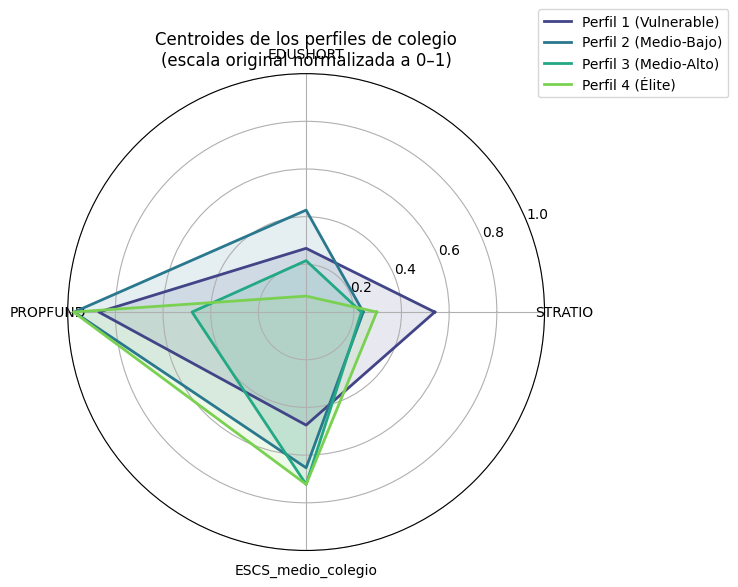

In [8]:
# --- Definición del sentido de ventaja socioestructural y etiquetas semánticas ---
# +1 -> mayor valor indica mayor ventaja socioestructural;
# -1 -> mayor valor indica menor ventaja; 0 -> neutralizado en el ranking jerárquico.
SENTIDO_VENTAJA_SOCIOESTRUCTURAL = {
    "STRATIO": -1,             # más alumnos por profesor -> menor ventaja
    "EDUSHORT": -1,            # mayor escasez de material educativo -> menor ventaja
    "PROPFUND": 0,             # neutralizado al ordenar perfiles (depende del modelo de cada país)
    "ESCS_medio_colegio": +1,  # mayor nivel socioeconómico -> mayor ventaja
}

PERFILES = [
    "Perfil 1 (Vulnerable)",
    "Perfil 2 (Medio-Bajo)",
    "Perfil 3 (Medio-Alto)",
    "Perfil 4 (Élite)",
]
PERFIL_A_NUMERO = {perfil: numero for numero, perfil in enumerate(PERFILES, start=1)}

# --- 7.1 Entrenamiento del modelo final (K = 4) ---
modelo_kmeans = KMeans(n_clusters=K_FINAL, random_state=RANDOM_STATE, n_init=10)
modelo_kmeans.fit(datos_transformados, sample_weight=pesos_colegio)
df_colegios["CLUSTER"] = modelo_kmeans.labels_

# --- 7.2 Inversión directa de centroides a la escala original ---
centroides_originales = pd.DataFrame(
    transformador_potencia.inverse_transform(
        escalador.inverse_transform(modelo_kmeans.cluster_centers_)
    ),
    columns=INDICES_FINALES,
)

# --- 7.3 Cálculo del Score de Ventaja Socioestructural ---
matriz_indices = df_colegios[INDICES_FINALES].to_numpy()
media_ponderada = np.average(matriz_indices, weights=pesos_colegio, axis=0)
desviacion_ponderada = np.sqrt(
    np.average((matriz_indices - media_ponderada) ** 2, weights=pesos_colegio, axis=0)
)

sentido_ventaja = pd.Series(SENTIDO_VENTAJA_SOCIOESTRUCTURAL).reindex(INDICES_FINALES)
n_indicadores_activos = int((sentido_ventaja != 0).sum())
centroides_tipificados = (centroides_originales[INDICES_FINALES] - media_ponderada) / desviacion_ponderada
centroides_originales["SCORE_VENTAJA"] = (
    (centroides_tipificados * sentido_ventaja).sum(axis=1) / n_indicadores_activos
)

# Ordenamiento de menor a mayor ventaja socioestructural y asignación de etiquetas
orden_clusters = centroides_originales["SCORE_VENTAJA"].sort_values().index
perfil_por_cluster = {int(cluster_id): perfil for cluster_id, perfil in zip(orden_clusters, PERFILES)}

df_colegios["PERFIL_COLEGIO"] = df_colegios["CLUSTER"].map(perfil_por_cluster)
centroides_originales["PERFIL_COLEGIO"] = centroides_originales.index.map(perfil_por_cluster)

# --- 7.4 Propagación del Perfil del Colegio a los Alumnos (Microdatos) ---
df_alumnos = df_alumnos.drop(columns=["PERFIL_COLEGIO"], errors="ignore").merge(
    df_colegios[["CNTSCHID", "PERFIL_COLEGIO"]],
    on="CNTSCHID",
    how="left",
    validate="many_to_one",
)

print(f"Perfiles asignados exitosamente a {df_alumnos['PERFIL_COLEGIO'].notna().sum():,} alumnos.")

# --- 7.5 Perfilado y distribución internacional ---
tamano_perfiles = df_colegios.groupby("PERFIL_COLEGIO").agg(
    N_COLEGIOS=("CNTSCHID", "size"),
    N_ALUMNOS=("N_ALUMNOS", "sum"),
    PESO_SENWT=("SENWT_col", "sum"),
)
tamano_perfiles["% PESO_SENWT"] = (
    100 * tamano_perfiles["PESO_SENWT"] / tamano_perfiles["PESO_SENWT"].sum()
)

tabla_perfiles = (
    centroides_originales.set_index("PERFIL_COLEGIO")
    .join(tamano_perfiles)
    .reindex(PERFILES)
)
print("Centroides en escala original, ordenados por Score de Ventaja Socioestructural:")
display(tabla_perfiles.round(3))

print("Distribución de colegios por país y perfil (% del peso SENWT de cada país):")
display(
    pd.crosstab(
        df_colegios["CNT"],
        df_colegios["PERFIL_COLEGIO"],
        values=df_colegios["SENWT_col"],
        aggfunc="sum",
        normalize="index",
    )
    .reindex(columns=PERFILES)
    .mul(100)
    .round(1)
)

# --- 7.6 Gráfico Radar (Araña) de los centroides originales ---
minimos = df_colegios[INDICES_FINALES].min()
maximos = df_colegios[INDICES_FINALES].max()
rangos = (maximos - minimos).replace(0, 1)

centroides_radar = (tabla_perfiles[INDICES_FINALES] - minimos) / rangos

angulos = np.linspace(0, 2 * np.pi, len(INDICES_FINALES), endpoint=False).tolist()
angulos_cerrados = angulos + angulos[:1]

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={"polar": True})

for perfil, color in zip(PERFILES, sns.color_palette("viridis", n_colors=len(PERFILES))):
    valores = centroides_radar.loc[perfil].tolist()
    valores_cerrados = valores + valores[:1]
    ax.plot(angulos_cerrados, valores_cerrados, linewidth=2, color=color, label=perfil)
    ax.fill(angulos_cerrados, valores_cerrados, color=color, alpha=0.12)

ax.set_xticks(angulos)
ax.set_xticklabels(INDICES_FINALES)
ax.set_ylim(0, 1)
ax.set_title("Centroides de los perfiles de colegio\n(escala original normalizada a 0–1)")
ax.legend(loc="upper right", bbox_to_anchor=(1.4, 1.15))
fig.tight_layout()
plt.show()

## 8. Construcción de Estratos Analíticos (País × Perfil Escolar × Género)

Para los análisis posteriores de rendimiento y equidad a nivel de estudiante, cruzamos tres dimensiones estructurales y demográficas:

1. **País (`CNT`):** captura el marco institucional y curricular nacional.
2. **Perfil del colegio (`PERFIL_COLEGIO`):** resume la tipología socioestructural del centro (`P1` a `P4`).
3. **Género del estudiante (`ST004D01T`):** permite desagregar brechas de género dentro de un mismo ecosistema escolar (`F` = Chicas, `M` = Chicos).

Se audita además qué estratos teóricos carecen de observaciones (p. ej., países sin colegios en el Perfil 1) y cuáles cuentan con menos de 30 alumnos (`MIN_ESTRATO_SIZE = 30`).

> **Justificación técnica (Refactorización — Supresión de lectura Parquet y `merge` duplicados):** Se reutiliza directamente la columna `ST004D01T` leída en la Sección 0 y la columna `PERFIL_COLEGIO` ya unida a `df_alumnos` en la Sección 7.4, eliminando la segunda lectura del archivo Parquet de estudiantes y el segundo `merge` redundante. Asimismo, la creación de `NOMBRE_ESTRATO` e `ID_ESTRATO` se vectoriza directamente sobre el subconjunto válido sin duplicar innecesariamente el `DataFrame`.

In [9]:
# --- 8.1 Recodificación del género y filtrado de alumnos asignables ---
GENERO_MAP = {1.0: "Chicas", 2.0: "Chicos"}
CODIGOS_GENERO = {"Chicas": "F", "Chicos": "M"}
MIN_ESTRATO_SIZE = 30

df_alumnos["GENERO_NOMBRE"] = df_alumnos["ST004D01T"].map(GENERO_MAP)

sin_perfil = df_alumnos["PERFIL_COLEGIO"].isna()
sin_genero = df_alumnos["GENERO_NOMBRE"].isna()
asignables = ~sin_perfil & ~sin_genero

print(f"Alumnos totales: {len(df_alumnos):,}")
print(f"  - Sin perfil (colegio eliminado): {sin_perfil.sum():,}")
print(f"  - Sin género informado: {sin_genero.sum():,}")
print(f"  - Asignados a un estrato: {asignables.sum():,} ({100 * asignables.mean():.1f}%)\n")

# --- 8.2 Construcción vectorizada de NOMBRE_ESTRATO e ID_ESTRATO ---
pais_valido = df_alumnos.loc[asignables, "CNT"].astype(str).str.strip()
perfil_valido = df_alumnos.loc[asignables, "PERFIL_COLEGIO"]
genero_valido = df_alumnos.loc[asignables, "GENERO_NOMBRE"]

numero_perfil = perfil_valido.map(PERFIL_A_NUMERO).astype(str)
codigo_genero = genero_valido.map(CODIGOS_GENERO)

df_alumnos.loc[asignables, "NOMBRE_ESTRATO"] = (
    pais_valido + " | " + perfil_valido + " | " + genero_valido
)
df_alumnos.loc[asignables, "ID_ESTRATO"] = (
    pais_valido + "_P" + numero_perfil + "_" + codigo_genero
)

# --- 8.3 Generación de la Tabla de Estratos ---
resumen_estratos = (
    df_alumnos.loc[asignables]
    .groupby(["CNT", "ID_ESTRATO", "NOMBRE_ESTRATO"], as_index=False)
    .agg(
        N_COLEGIOS=("CNTSCHID", "nunique"),
        N_ALUMNOS=("ID_ESTRATO", "size"),
    )
    .sort_values(["CNT", "ID_ESTRATO"], ignore_index=True)
)

print("Tabla resumen de estratos generados:")
display(resumen_estratos)

# --- 8.4 Control de calidad: Tamaño muestral y estratos vacíos ---
ids_teoricos = {
    f"{p}_P{n}_{g}"
    for p in pais_valido.unique()
    for n in range(1, K_FINAL + 1)
    for g in CODIGOS_GENERO.values()
}

estratos_vacios = sorted(ids_teoricos - set(resumen_estratos["ID_ESTRATO"]))
if estratos_vacios:
    warnings.warn(f"Hay {len(estratos_vacios)} estrato(s) teóricos vacíos: {estratos_vacios}")

estratos_pequenos = resumen_estratos[resumen_estratos["N_ALUMNOS"] < MIN_ESTRATO_SIZE]
if not estratos_pequenos.empty:
    warnings.warn(f"Hay {len(estratos_pequenos)} estrato(s) con < {MIN_ESTRATO_SIZE} alumnos.")
    display(estratos_pequenos.sort_values("N_ALUMNOS"))
else:
    print(f"\n✅ Todos los estratos generados cuentan con al menos {MIN_ESTRATO_SIZE} alumnos.")

Alumnos totales: 268,610
  - Sin perfil (colegio eliminado): 87,867
  - Sin género informado: 78
  - Asignados a un estrato: 180,719 (67.3%)



Tabla resumen de estratos generados:


,CNT,ID_ESTRATO,NOMBRE_ESTRATO,N_COLEGIOS,N_ALUMNOS
0,AUS,AUS_P1_F,AUS | Perfil 1 (Vulnerable) | Chicas,6,40
1,AUS,AUS_P1_M,AUS | Perfil 1 (Vulnerable) | Chicos,6,40
2,AUS,AUS_P2_F,AUS | Perfil 2 (Medio-Bajo) | Chicas,118,895
3,AUS,AUS_P2_M,AUS | Perfil 2 (Medio-Bajo) | Chicos,123,1110
4,AUS,AUS_P3_F,AUS | Perfil 3 (Medio-Alto) | Chicas,148,1794
...,...,...,...,...,...
201,USA,USA_P2_M,USA | Perfil 2 (Medio-Bajo) | Chicos,24,332
202,USA,USA_P3_F,USA | Perfil 3 (Medio-Alto) | Chicas,6,72
203,USA,USA_P3_M,USA | Perfil 3 (Medio-Alto) | Chicos,6,80
204,USA,USA_P4_F,USA | Perfil 4 (Élite) | Chicas,59,892


C:\Users\victo\AppData\Local\Temp\ipykernel_9188\1302644070.py:56: UserWarning: Hay 18 estrato(s) teóricos vacíos: ['BEL_P1_F', 'BEL_P1_M', 'EST_P1_F', 'EST_P1_M', 'FIN_P1_F', 'FIN_P1_M', 'FIN_P3_F', 'FIN_P3_M', 'ISL_P1_F', 'ISL_P1_M', 'KOR_P1_F', 'KOR_P1_M', 'MEX_P4_F', 'MEX_P4_M', 'SWE_P1_F', 'SWE_P1_M', 'SWE_P3_F', 'SWE_P3_M']
  warnings.warn(f"Hay {len(estratos_vacios)} estrato(s) teóricos vacíos: {estratos_vacios}")
C:\Users\victo\AppData\Local\Temp\ipykernel_9188\1302644070.py:60: UserWarning: Hay 13 estrato(s) con < 30 alumnos.
  warnings.warn(f"Hay {len(estratos_pequenos)} estrato(s) con < {MIN_ESTRATO_SIZE} alumnos.")


,CNT,ID_ESTRATO,NOMBRE_ESTRATO,N_COLEGIOS,N_ALUMNOS
142,NLD,NLD_P3_F,NLD | Perfil 3 (Medio-Alto) | Chicas,1,1
143,NLD,NLD_P3_M,NLD | Perfil 3 (Medio-Alto) | Chicos,1,2
47,DNK,DNK_P1_M,DNK | Perfil 1 (Vulnerable) | Chicos,2,7
46,DNK,DNK_P1_F,DNK | Perfil 1 (Vulnerable) | Chicas,1,8
43,DEU,DEU_P3_M,DEU | Perfil 3 (Medio-Alto) | Chicos,1,10
111,ITA,ITA_P1_M,ITA | Perfil 1 (Vulnerable) | Chicos,2,12
107,ISL,ISL_P3_M,ISL | Perfil 3 (Medio-Alto) | Chicos,2,14
89,GRC,GRC_P1_M,GRC | Perfil 1 (Vulnerable) | Chicos,1,16
88,GRC,GRC_P1_F,GRC | Perfil 1 (Vulnerable) | Chicas,1,16
106,ISL,ISL_P3_F,ISL | Perfil 3 (Medio-Alto) | Chicas,3,17


### Nota metodológica sobre la retención muestral

Quitar el género solo recuperaría 78 alumnos, y eliminar otra variable estructural del colegio destruiría la validez analítica de los perfiles solo para inflar artificialmente la muestra:

* **El espejismo del género:** Los alumnos con colegio válido pero sin género informado son únicamente **24** (78 en toda la muestra bruta, un irrelevante **0,03 %** del total). Prescindir del género haría perder una dimensión demográfica crítica en el análisis educativo (como la brecha de rendimiento por sexo) a cambio de un impacto nulo en la retención.
* **El límite de las variables escolares:** La pérdida real (**87.867 alumnos**) proviene de los colegios y países que no reportaron datos clave como la financiación pública (`PROPFUND`), la ratio alumno-profesor (`STRATIO`) o la escasez de material educativo (`EDUSHORT`). Ya se asumió el sacrificio metodológico óptimo al eliminar `STAFFSHORT` para rescatar a 5 países completos. Suprimir otra variable estructural para forzar un 80 % de retención desvirtuaría las tipologías y dejaría de capturar la complejidad real del ecosistema escolar.

## 9. Exportación de Artefactos del Modelo

> **Justificación técnica (Exportación robusta y reproducible):** Para garantizar que futuras ediciones de PISA (o pipelines de inferencia en producción) proyecten los colegios exactamente en el mismo espacio métrico de PISA 2022 sin fugas de datos (*data leakage*), se serializan en `../../models/` (`./models/` en la raíz del repositorio) los tres estimadores de `scikit-learn` (`PowerTransformer`, `StandardScaler` y `KMeans`) mediante `joblib`, junto con dos ficheros JSON legibles y auditables que contienen los límites exactos de winsorización (P1–P99) y el mapeo semántico de clústeres a perfiles ordenados por el *Score de Ventaja Socioestructural*.

In [10]:
RUTA_MODELOS.mkdir(parents=True, exist_ok=True)

# 1. Exportación de estimadores de scikit-learn con joblib
rutas_joblib = {
    "kmeans": RUTA_MODELOS / "kmeans_perfiles_colegio.joblib",
    "scaler": RUTA_MODELOS / "standard_scaler_colegio.joblib",
    "power_transformer": RUTA_MODELOS / "power_transformer_colegio.joblib",
}
joblib.dump(modelo_kmeans, rutas_joblib["kmeans"])
joblib.dump(escalador, rutas_joblib["scaler"])
joblib.dump(transformador_potencia, rutas_joblib["power_transformer"])

# 2. Exportación de límites de winsorización (JSON)
ruta_winsor_json = RUTA_MODELOS / "limites_winsorizacion.json"
payload_winsor = {
    "percentiles": PERCENTILES_WINSOR,
    "variables": {
        var: {"min": float(lim[0]), "max": float(lim[1])}
        for var, lim in limites_winsor.items()
    },
}
with open(ruta_winsor_json, "w", encoding="utf-8") as f:
    json.dump(payload_winsor, f, indent=4, ensure_ascii=False)

# 3. Exportación del mapeo de clústeres y metadatos del Score de Ventaja Socioestructural (JSON)
ruta_mapeo_json = RUTA_MODELOS / "mapeo_clusters_perfiles.json"
payload_mapeo = {
    "k_final": K_FINAL,
    "indices_finales": INDICES_FINALES,
    "sentido_ventaja_socioestructural": SENTIDO_VENTAJA_SOCIOESTRUCTURAL,
    "cluster_a_perfil": {str(k): v for k, v in perfil_por_cluster.items()},
    "perfil_a_numero": PERFIL_A_NUMERO,
}
with open(ruta_mapeo_json, "w", encoding="utf-8") as f:
    json.dump(payload_mapeo, f, indent=4, ensure_ascii=False)

print(f"✅ Artefactos exportados exitosamente en: {RUTA_MODELOS.resolve()}")
for archivo in sorted(RUTA_MODELOS.iterdir()):
    if archivo.is_file():
        print(f"  - {archivo.name:<36} ({archivo.stat().st_size:,} bytes)")

✅ Artefactos exportados exitosamente en: C:\Users\victo\Documents\Master_Nuclio\TFM\models
  - kmeans_perfiles_colegio.joblib       (27,847 bytes)
  - limites_winsorizacion.json           (287 bytes)
  - mapeo_clusters_perfiles.json         (668 bytes)
  - power_transformer_colegio.joblib     (439 bytes)
  - standard_scaler_colegio.joblib       (679 bytes)


## 10. Guía de Reutilización: Inferencia de Perfiles en Futuras Ediciones de PISA

Para clasificar colegios de otras ediciones de PISA (por ejemplo, PISA 2018 o PISA 2025) manteniendo **comparabilidad longitudinal estricta** con la línea base de PISA 2022, el equipo debe aplicar el pipeline en **modo inferencia**. Esto implica tres reglas de oro innegociables:

1. **Respeto absoluto a los límites del JSON (`limites_winsorizacion.json`):** Nunca recalcules los percentiles P1 y P99 sobre el nuevo conjunto de datos. Recorta (`clip`) `STRATIO` y `PROPFUND` utilizando exactamente las cotas `min` y `max` almacenadas en el JSON de 2022.
2. **Uso obligatorio de `.transform()` y `.predict()` (prohibido usar `.fit()` o `.fit_transform()`):** Reajustar el `PowerTransformer`, el `StandardScaler` o el `KMeans` con los datos de otra edición alteraría los exponentes $\lambda$, las medias internacionales y la posición de los centroides, invalidando cualquier comparación interanual.
3. **Orden exacto de columnas y mapeo desde JSON:** Asegúrate de pasar las 4 variables exactamente en el orden registrado en `indices_finales` (`["STRATIO", "EDUSHORT", "PROPFUND", "ESCS_medio_colegio"]`) tras descartar filas con nulos, y traduce el identificador numérico devuelto por `modelo_kmeans.predict(...)` mediante `mapeo_clusters_perfiles.json`.

### Snippet de ejemplo para inferencia en nuevas ediciones

```python
import json
from pathlib import Path
import joblib
import pandas as pd

RUTA_MODELOS = Path("../../models")

# 1. Cargar artefactos serializados y configuración JSON
transformador_potencia = joblib.load(RUTA_MODELOS / "power_transformer_colegio.joblib")
escalador = joblib.load(RUTA_MODELOS / "standard_scaler_colegio.joblib")
modelo_kmeans = joblib.load(RUTA_MODELOS / "kmeans_perfiles_colegio.joblib")

with open(RUTA_MODELOS / "limites_winsorizacion.json", "r", encoding="utf-8") as f:
    config_winsor = json.load(f)["variables"]

with open(RUTA_MODELOS / "mapeo_clusters_perfiles.json", "r", encoding="utf-8") as f:
    config_mapeo = json.load(f)

indices_finales = config_mapeo["indices_finales"]
cluster_a_perfil = {int(k): v for k, v in config_mapeo["cluster_a_perfil"].items()}

def inferir_perfiles_colegio(df_nuevos_colegios: pd.DataFrame) -> pd.DataFrame:
    """
    Asigna el perfil escolar de referencia (PISA 2022) a un DataFrame a nivel de colegio.
    Requiere las columnas: ['CNTSCHID', 'STRATIO', 'EDUSHORT', 'PROPFUND', 'ESCS_medio_colegio'].
    """
    df_valido = df_nuevos_colegios.dropna(subset=indices_finales).copy()

    # Paso A: Aplicar límites de winsorización históricos del JSON (SIN recalcular cuantiles)
    for variable, cotas in config_winsor.items():
        df_valido[variable] = df_valido[variable].clip(lower=cotas["min"], upper=cotas["max"])

    # Paso B: Transformar (USO OBLIGATORIO de .transform(), NUNCA .fit_transform())
    X_bruto = df_valido[indices_finales].to_numpy()
    X_potencia = transformador_potencia.transform(X_bruto)
    X_escalado = escalador.transform(X_potencia)

    # Paso C: Predecir clúster y mapear a la etiqueta semántica de Ventaja Socioestructural
    df_valido["CLUSTER"] = modelo_kmeans.predict(X_escalado)
    df_valido["PERFIL_COLEGIO"] = df_valido["CLUSTER"].map(cluster_a_perfil)
    return df_valido
```